<a href="https://colab.research.google.com/github/siqi-lYuYl/COMP551_A3/blob/main/COMP551_A3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# QUICK_RUN = True trains on small subsets for 1-2 epochs, just to check that every cell runs (a few minutes).
# Set it to False for the real results.
QUICK_RUN = False

# Task 1: Acquire the data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split

# normalise data

# load training data only and calculate its mean and std
temp_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())


# ADDED: split before computing mean/std, so the validation images are not used for the statistics.
# Same sizes and same seed as the split further down, so both splits pick exactly the same images.
train_size = int(0.8* len(temp_train))
val_size = len(temp_train) - train_size
temp_train_split, temp_val_split = random_split(temp_train,[train_size, val_size],
                                                generator = torch.Generator().manual_seed(2026))


sum_val = 0.0
squared_sum = 0.0
N = 0
temp_loader = DataLoader(temp_train_split, batch_size = 1000, shuffle = False)
for data, _ in temp_loader:
  sum_val += data.sum(dim = [0,2,3])
  squared_sum +=(data **2).sum(dim=[0,2,3])
  N += data.numel()

mean = (sum_val / N).item()
std = (torch.sqrt((squared_sum / N) - (mean **2))).item()
print(mean)
print(std)

# transform function that normalize the data according to training set's mean and std
train_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((mean,), (std,))]
)

# Load both test and train set using the transform function above (both using training set's stat)
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True,
                transform=train_transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True,
                                     transform = train_transform)

0.2860829830169678
0.35309210419654846


In [3]:
# Train Validation Split
train_size = int(0.8* len(train_dataset))
val_size = len(train_dataset) - train_size

train_data, val_data = random_split(train_dataset,[train_size, val_size],
                                    generator = torch.Generator().manual_seed(2026))

# Flatten for Numpy MLP

def to_numpy(dataset):
  X, y = next(iter(DataLoader(dataset, batch_size = len(dataset),shuffle = False)))
  return X.view(len(X),-1).numpy(), y.numpy()

X_train, y_train = to_numpy(train_data)
X_val, y_val = to_numpy(val_data)
X_test, y_test = to_numpy(test_dataset)
print(X_train.shape, X_val.shape, X_test.shape)


# ADDED: unnormalized copies (raw pixel values 0..255) for Q4.
# temp_train_split / temp_val_split only use ToTensor (values in [0, 1]), so multiply by 255.
temp_test = datasets.FashionMNIST(root="./data", train=False, download=True,
                                  transform=transforms.ToTensor())
X_train_raw, _ = to_numpy(temp_train_split)
X_val_raw, _ = to_numpy(temp_val_split)
X_test_raw, _ = to_numpy(temp_test)
X_train_raw, X_val_raw, X_test_raw = X_train_raw * 255, X_val_raw * 255, X_test_raw * 255
print('raw pixel range:', X_train_raw.min(), X_train_raw.max())

(48000, 784) (12000, 784) (10000, 784)
raw pixel range: 0.0 255.0


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


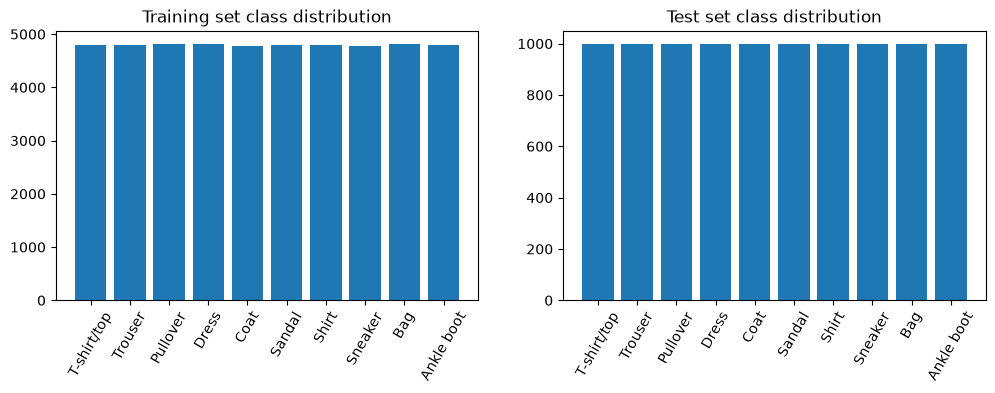

In [4]:
class_names = temp_train.classes
print(class_names)

# ADDED: class distribution plot for the "Datasets" section of the report
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(class_names, np.bincount(y_train, minlength=10))
axes[0].set_title('Training set class distribution')
axes[0].tick_params(axis='x', rotation=60)
axes[1].bar(class_names, np.bincount(y_test, minlength=10))
axes[1].set_title('Test set class distribution')
axes[1].tick_params(axis='x', rotation=60)
plt.show()

#Task 2: Implement a Multilayer Perceptron


In [5]:
# helper functions
def relu (a):
  return np.maximum(0,a)

def relu_grad(a):
  return (a>0).astype(float) # a > 0, slope = 1 otherwise = 0

def softmax(logits):
  exp_logits = np.exp(logits - np.max(logits, axis = 1, keepdims = True))
  return exp_logits / np.sum(exp_logits,  axis = 1, keepdims = True)

def one_hot(y,c):
  return np.eye(c)[y]

def evaluate_acc(true, target) :
  return np.sum(true == target)/ len(true)


# More for Q2
# ADDED: tanh and its gradient
def tanh(a):
  return np.tanh(a)

def tanh_grad(a):
  return 1 - np.tanh(a) ** 2


# ADDED: Leaky-ReLU and its gradient
def leaky_relu(a, slope = 0.01):
  return np.where(a > 0, a, slope * a)

def leaky_relu_grad(a, slope = 0.01):
  return np.where(a > 0, 1.0, slope)   # a > 0, slope = 1 otherwise = 0.01



## MLP Class

In [6]:
class MLP:
  def __init__(self, activation, activation_grad, nhidden_layers, hidden_units,
               input_dim = 784, num_classes = 10,
               l1 = 0.0, l2 = 0.0) :

    self.activation = activation
    self.activation_grad = activation_grad
    assert nhidden_layers == len(hidden_units)
    self.l1 = l1
    self.l2 = l2

    # every layers size
    size = [input_dim] + hidden_units + [num_classes]

    # weight matrix + bias for neighbouring layers

    self.weights = []
    self.biases = []

    for i in range(len(size)-1):
      dim_in = size[i]
      dim_out = size[i+1]

      W = np.random.randn(dim_in, dim_out) * np.sqrt(2/dim_in)
      b = np.zeros(dim_out)

      self.weights.append(W)
      self.biases.append(b)

  def forward(self, X):
    a_list = []
    z_list = [X]

    z = X

    for l in range(len(self.weights)):
      a = np.dot(z, self.weights[l]) + self.biases[l] # inputs * weights
      if l < len(self.weights) - 1 :                  # check if its hidden layer
        z = self.activation(a)
      else:                                           # last layer
        z = softmax(a)
      a_list.append(a)
      z_list.append(z)

    return a_list, z_list

  def backward(self, X, y):
    N = X.shape[0]

    #forward pass
    a_list, z_list = self.forward(X)
    yh = z_list[-1]                     # predicted probabilities

    dW = [None] * len(self.weights)
    db = [None] * len(self.weights)

    dy = yh - y

    for l in reversed(range(len(self.weights))):
      dW[l] = np.dot(z_list[l].T, dy) / N
      dW[l] += self.l2 * self.weights[l] + self.l1 * np.sign(self.weights[l]) #ADDED: l1 and l2 reg
      db[l] = np.sum(dy, axis = 0 ) / N # average error/ unit
      if l > 0:
        dz = np.dot(dy, self.weights[l].T)
        dy = dz * self.activation_grad(a_list[l-1])

    return dW, db





  def fit(self, X, y, lr, epochs, batch_size,
          X_eval = None, y_eval = None):
    N = X.shape[0]
    Y = one_hot(y,10)
    self.train_acc = []
    self.eval_acc = []

    for epoch in range(epochs):
      perm = np.random.permutation(N)
      for start in range (0,N, batch_size):
        i = perm[start:start + batch_size]

        dW, db = self.backward(X[i], Y[i]) # grad of current batch

        for l in range(len(self.weights)):
          self.weights[l] -= lr * dW[l]
          self.biases[l] -= lr * db[l]

      acc = evaluate_acc(y, self.predict(X))
      self.train_acc.append(acc)

      # print(epoch, acc)

      if X_eval is not None:
        self.eval_acc.append(evaluate_acc(y_eval, self.predict(X_eval)))

    return self

  def predict(self, X):
    a_list, z_list = self.forward(X) # predicted class for each input with the highest probability

    return np.argmax(z_list[-1], axis = 1)


In [7]:
# #test
# np.random.seed(0)
# m = MLP( relu , relu_grad, 2, [256,256])
# m.fit(X_train, y_train, lr = 0.01, epochs = 10, batch_size = 64)
# print(evaluate_acc(y_val,m.predict(X_val)))

# Task 3: Run the experiments and report


### Common settings



In [8]:
import time

BATCH_SIZE = 64
EPOCHS = 2 if QUICK_RUN else 20
TUNING_EPOCHS = 2 if QUICK_RUN else 5

if QUICK_RUN:
  X_train, y_train, X_train_raw = X_train[:5000], y_train[:5000], X_train_raw[:5000]
  X_val, y_val, X_val_raw = X_val[:1000], y_val[:1000], X_val_raw[:1000]
  X_test, y_test, X_test_raw = X_test[:1000], y_test[:1000], X_test_raw[:1000]

results = {}   # model name -> {'test_acc', 'time', 'history': {'train_acc': [...], 'eval_acc': [...]}}

### Plotting function


In [9]:
def plot_histories(names, title, eval_name = 'test'):
  # names: model names in `results`. Same colour for one model: train dashed, eval solid.
  plt.figure(figsize = (7, 4))
  for i, name in enumerate(names):
    hist = results[name]['history']
    epochs = np.arange(1, len(hist['train_acc']) + 1)
    plt.plot(epochs, hist['train_acc'], '--', color = f'C{i}', label = f'{name} (train)')
    plt.plot(epochs, hist['eval_acc'], '-', color = f'C{i}', label = f'{name} ({eval_name})')
  plt.xlabel('epoch')
  plt.ylabel('accuracy')
  plt.title(title)
  plt.legend(fontsize = 8)
  plt.grid(alpha = .3)
  plt.show()


### Choosing the learning rate (validation set)


lr = 0.005: validation accuracy per epoch [0.8228 0.8402 0.8544 0.8599 0.8617]
lr = 0.01: validation accuracy per epoch [0.8429 0.8577 0.8651 0.8634 0.8743]
lr = 0.05: validation accuracy per epoch [0.8563 0.8658 0.8783 0.8801 0.8861]
lr = 0.1: validation accuracy per epoch [0.8598 0.8583 0.8868 0.8866 0.8742]


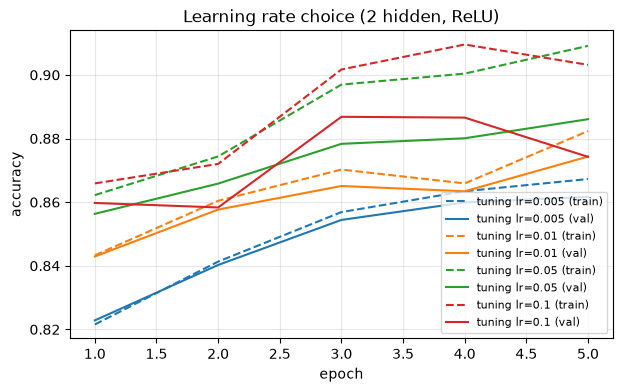

In [10]:
np.random.seed(0)
lr_candidates = [0.005, 0.01, 0.05, 0.1]
for lr in lr_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256])
  model.fit(X_train, y_train, lr, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  results[f'tuning lr={lr}'] = {'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  print(f'lr = {lr}: validation accuracy per epoch', np.round(model.eval_acc, 4))

plot_histories([f'tuning lr={lr}' for lr in lr_candidates], 'Learning rate choice (2 hidden, ReLU)', eval_name = 'val')

for lr in lr_candidates:
  del results[f'tuning lr={lr}']   # tuning runs are not part of the final results table

### Training function

In [11]:
LEARNING_RATE = 0.05

def run_experiment(name, model, X_tr, y_tr, X_te, y_te, lr = LEARNING_RATE, epochs = EPOCHS):
  print(f'===== {name} =====')
  start = time.time()
  model.fit(X_tr, y_tr, lr, epochs, BATCH_SIZE, X_eval = X_te, y_eval = y_te)
  train_time = time.time() - start
  test_acc = evaluate_acc(y_te, model.predict(X_te))
  print(f'--> test accuracy {test_acc:.4f}, training time {train_time:.1f}s\n')
  results[name] = {'test_acc': test_acc, 'time': train_time,
                   'history': {'train_acc': model.train_acc, 'eval_acc': model.eval_acc}}
  return model


## MLP SECTION (Q1-Q5)

### Q1: Depth

1. no hidden layer
2. one hidden layer with 256 ReLU units
3. two hidden layers with 256 ReLU units each

===== 0 hidden =====
--> test accuracy 0.8404, training time 3.1s

===== 1 hidden ReLU =====
--> test accuracy 0.8810, training time 33.2s

===== 2 hidden ReLU =====
--> test accuracy 0.8784, training time 45.3s



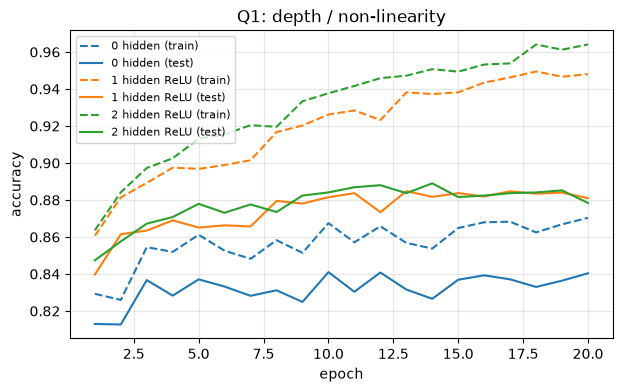

In [12]:
np.random.seed(1)
run_experiment('0 hidden', MLP(relu, relu_grad, 0, []), X_train, y_train, X_test, y_test)
run_experiment('1 hidden ReLU', MLP(relu, relu_grad, 1, [256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU', MLP(relu, relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['0 hidden', '1 hidden ReLU', '2 hidden ReLU'], 'Q1: depth / non-linearity')

### Q2: Activation functions (all 2 hidden layers)
1. ReLU
2. tanh
3. Leaky-ReLU

===== 2 hidden tanh =====
--> test accuracy 0.8779, training time 51.1s

===== 2 hidden LeakyReLU =====
--> test accuracy 0.8883, training time 46.8s



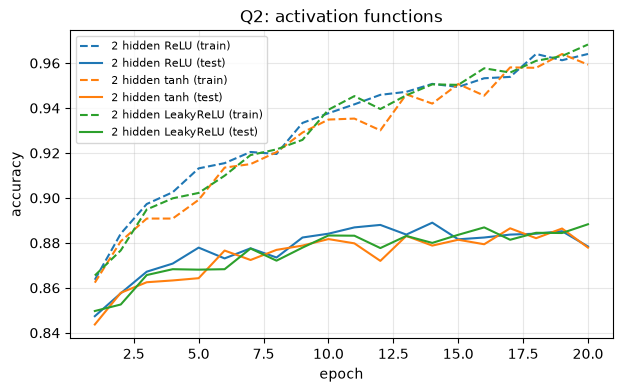

In [13]:
np.random.seed(2)
run_experiment('2 hidden tanh', MLP(tanh, tanh_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)
run_experiment('2 hidden LeakyReLU', MLP(leaky_relu, leaky_relu_grad, 2, [256, 256]), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden tanh', '2 hidden LeakyReLU'], 'Q2: activation functions')

### Q3: L1 and L2 regularization

First choose the strength $\lambda$ for each type on the **validation** set, then train the final models.

lambda = 0: validation accuracy L1 0.8858, L2 0.8879
lambda = 1e-05: validation accuracy L1 0.8842, L2 0.8807
lambda = 0.0001: validation accuracy L1 0.8831, L2 0.8904
lambda = 0.001: validation accuracy L1 0.8357, L2 0.8826
lambda = 0.01: validation accuracy L1 0.7544, L2 0.8653
lambda = 0.1: validation accuracy L1 0.0982, L2 0.7563


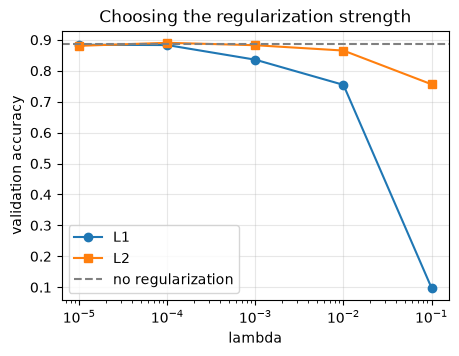

chosen lambda for L1: 1e-05   for L2: 0.0001


In [14]:
# Choose Lambda
np.random.seed(3)
lambda_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
val_acc_l1 = []
val_acc_l2 = []
for lam in lambda_candidates:
  model = MLP(relu, relu_grad, 2, [256, 256], l1 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l1.append(model.eval_acc[-1])

  model = MLP(relu, relu_grad, 2, [256, 256], l2 = lam)
  model.fit(X_train, y_train, LEARNING_RATE, TUNING_EPOCHS, BATCH_SIZE, X_eval = X_val, y_eval = y_val)
  val_acc_l2.append(model.eval_acc[-1])

  print(f'lambda = {lam}: validation accuracy L1 {val_acc_l1[-1]:.4f}, L2 {val_acc_l2[-1]:.4f}')

nonzero = lambda_candidates[1:]

plt.figure(figsize = (5, 3.5))
plt.semilogx(nonzero, val_acc_l1[1:], 'o-', label = 'L1')
plt.semilogx(nonzero, val_acc_l2[1:], 's-', label = 'L2')

plt.axhline(val_acc_l1[0], color = 'gray', linestyle = '--', label = 'no regularization')   # lambda = 0 baseline

plt.xlabel('lambda'); plt.ylabel('validation accuracy'); plt.legend(); plt.grid(alpha = .3)
plt.title('Choosing the regularization strength')
plt.show()

# choose among the nonzero lambdas, so the L1 / L2 models are actually regularized
best_l1 = nonzero[int(np.argmax(val_acc_l1[1:]))]
best_l2 = nonzero[int(np.argmax(val_acc_l2[1:]))]
print('chosen lambda for L1:', best_l1, '  for L2:', best_l2)

===== 2 hidden ReLU + L1 =====
--> test accuracy 0.8911, training time 46.2s

===== 2 hidden ReLU + L2 =====
--> test accuracy 0.8847, training time 44.6s



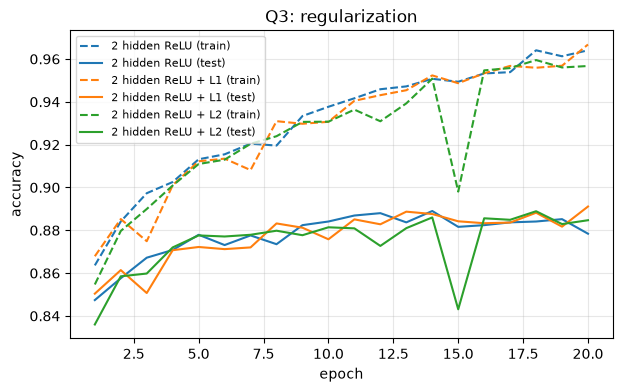

In [15]:
np.random.seed(30)
run_experiment('2 hidden ReLU + L1', MLP(relu, relu_grad, 2, [256, 256], l1 = best_l1), X_train, y_train, X_test, y_test)
run_experiment('2 hidden ReLU + L2', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2), X_train, y_train, X_test, y_test)

plot_histories(['2 hidden ReLU', '2 hidden ReLU + L1', '2 hidden ReLU + L2'], 'Q3: regularization')

### Q4: Training on unnormalized images

2 hidden layer ReLU MLP on the raw pixel values 0..255 (`X_train_raw` from Task 1), with the same learning rate.


### *Q4 Bonus Test* (Try different learning rates)

The inputs are 255 times larger, so the first-layer pre-activations and gradients are much larger and the same step size
can blow up training. We also try a much smaller learning rate to see whether the step size is the only problem.

===== 2 hidden ReLU, unnormalized =====
--> test accuracy 0.1000, training time 36.9s

===== 2 hidden ReLU, unnormalized, lr=1e-5 =====
--> test accuracy 0.7812, training time 44.8s



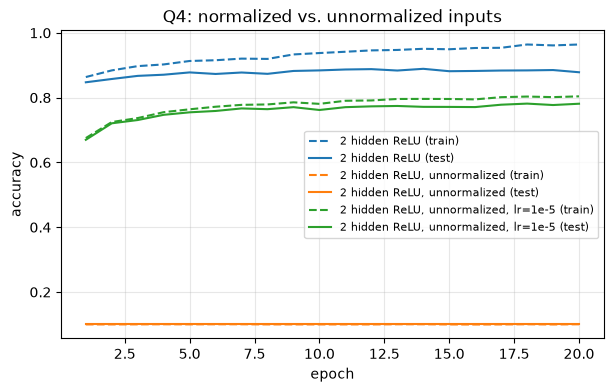

In [16]:
np.random.seed(4)
run_experiment('2 hidden ReLU, unnormalized', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test)
run_experiment('2 hidden ReLU, unnormalized, lr=1e-5', MLP(relu, relu_grad, 2, [256, 256]),
               X_train_raw, y_train, X_test_raw, y_test, lr = 1e-5)

plot_histories(['2 hidden ReLU', '2 hidden ReLU, unnormalized', '2 hidden ReLU, unnormalized, lr=1e-5'],
               'Q4: normalized vs. unnormalized inputs')

### Q5: Data augmentation


training set with augmentation: (96000, 784)


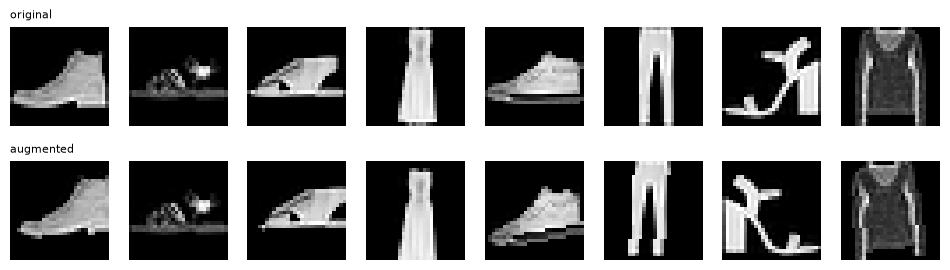

In [17]:
augmentation = [transforms.RandomHorizontalFlip(),
                transforms.RandomAffine(degrees = 10, translate = (0.1, 0.1))]

aug_transform = transforms.Compose(augmentation + [transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
aug_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=aug_transform)

# only select the images already in the training set (don't leak validation set)
aug_data = torch.utils.data.Subset(aug_dataset, train_data.indices[:len(X_train)])
X_aug, y_aug = to_numpy(aug_data)
assert np.all(y_aug == y_train)

X_train_with_aug = np.concatenate([X_train, X_aug])
y_train_with_aug = np.concatenate([y_train, y_aug])
print('training set with augmentation:', X_train_with_aug.shape)

# samples of original image v.s. augmented image
# to show the effect of augmentation
fig, axes = plt.subplots(2, 8, figsize = (12, 3.2))
for i in range(8):
  axes[0, i].imshow(X_train[i].reshape(28, 28), cmap = 'gray'); axes[0, i].axis('off')
  axes[1, i].imshow(X_aug[i].reshape(28, 28), cmap = 'gray'); axes[1, i].axis('off')
axes[0, 0].set_title('original', fontsize = 8, loc = 'left')
axes[1, 0].set_title('augmented', fontsize = 8, loc = 'left')
plt.show()

Re-train MLP from Q3 on that augmented data

===== 2 hidden ReLU + L2 + augmentation =====
--> test accuracy 0.8804, training time 95.0s



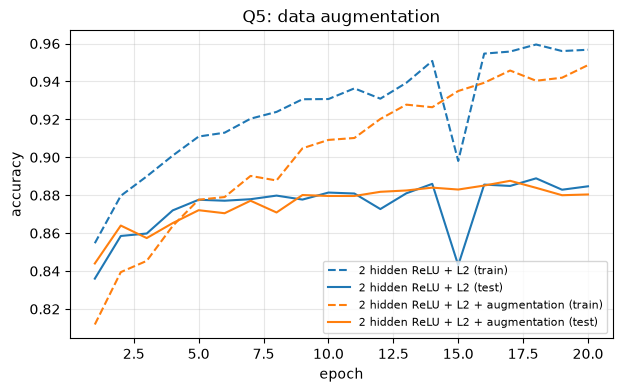

In [18]:
np.random.seed(5)
run_experiment('2 hidden ReLU + L2 + augmentation', MLP(relu, relu_grad, 2, [256, 256], l2 = best_l2),
               X_train_with_aug, y_train_with_aug, X_test, y_test)

plot_histories(['2 hidden ReLU + L2', '2 hidden ReLU + L2 + augmentation'], 'Q5: data augmentation')

## CNN SECTION (Q6-Q9)

### Setup

In [ ]:
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision

torch.manual_seed(0)
if torch.cuda.is_available():
  device = torch.device('cuda')
elif torch.backends.mps.is_available():      # Apple Silicon GPU
  device = torch.device('mps')
else:
  device = torch.device('cpu')
print(f'Using device: {device}')

### Data loader

In [ ]:
def make_loaders(train_tf, eval_tf, batch_size = 64):
  # two copies of the training partition: one with the training transform, one with the evaluation transform
  train_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=train_tf)
  eval_full = datasets.FashionMNIST(root="./data", train=True, download=True, transform=eval_tf)
  test_full = datasets.FashionMNIST(root="./data", train=False, download=True, transform=eval_tf)

  train_idx = train_data.indices                # same split as Part 1 (Task 1)
  val_idx = val_data.indices
  test_idx = list(range(len(test_full)))
  if QUICK_RUN:
    train_idx, val_idx, test_idx = train_idx[:2000], val_idx[:500], test_idx[:500]

  trainloader = DataLoader(torch.utils.data.Subset(train_full, train_idx), batch_size = batch_size, shuffle = True, num_workers = 2)
  valloader = DataLoader(torch.utils.data.Subset(eval_full, val_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  testloader = DataLoader(torch.utils.data.Subset(test_full, test_idx), batch_size = batch_size, shuffle = False, num_workers = 2)
  return trainloader, valloader, testloader

trainloader, valloader, testloader = make_loaders(train_transform, train_transform)   # Task 1 normalization
trainloader_aug, _, _ = make_loaders(aug_transform, train_transform)                  # Q5 augmentation
print('training batches:', len(trainloader), ' validation batches:', len(valloader), ' test batches:', len(testloader))

### Training and evaluation function

In [ ]:
def evaluate_accuracy(model, loader):
  model.eval()
  true_labels = []
  predictions = []
  with torch.no_grad():
    for images, labels in loader:
      outputs = model(images.to(device))
      predictions.append(outputs.argmax(dim = 1).cpu().numpy())   # class with the highest score
      true_labels.append(labels.numpy())
  return evaluate_acc(np.concatenate(true_labels), np.concatenate(predictions))   # Part 1 accuracy function


def train_model(model, trainloader, evalloader, num_epochs = 5, lr = 0.01):
  criterion = nn.CrossEntropyLoss()
  # only parameters with requires_grad=True are trained (matters for the frozen pre-trained model)
  trainable = [p for p in model.parameters() if p.requires_grad]
  optimizer = optim.SGD(trainable, lr = lr, momentum = 0.9)

  history = {'train_acc': [], 'eval_acc': []}
  start = time.time()
  for epoch in range(num_epochs):
    # ===== Training phase =====
    model.train()
    true_labels = []
    predictions = []
    for images, labels in trainloader:
      images = images.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()
      outputs = model(images)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()

      predictions.append(outputs.argmax(dim = 1).cpu().numpy())
      true_labels.append(labels.cpu().numpy())

    # ===== Evaluation phase =====
    history['train_acc'].append(evaluate_acc(np.concatenate(true_labels), np.concatenate(predictions)))
    history['eval_acc'].append(evaluate_accuracy(model, evalloader))
    print(f'Epoch [{epoch + 1}/{num_epochs}] - train acc {history["train_acc"][-1]:.4f}, '
          f'eval acc {history["eval_acc"][-1]:.4f}, time so far {time.time() - start:.0f}s')

  history['time'] = time.time() - start
  return history

### Q6: CNN with 2 convolutional layers
